# Set 7: EDA + MLP Classifier (optimised)

**Q1 → Exp 1A / 1B** · **Q2 → Exp 5** (MLP)

Datasets: Q1 `IRIS.csv`, Q2 `Diabetes.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/IRIS.csv")
print(df.shape)
df.head()

(150, 5)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### Q1.2 Features with high negative correlation and no correlation

In [3]:
corr = df.select_dtypes("number").corr()
print(corr.round(2), "\n")
found = {"high positive": [], "high negative": [], "no correlation": []}
for a in corr.columns:
    for b in corr.columns:
        if a < b:                                   # each pair once
            r = corr.loc[a, b]
            if r > 0.5:
                found["high positive"].append(f"{a} & {b} ({r:.2f})")
            elif r < -0.5:
                found["high negative"].append(f"{a} & {b} ({r:.2f})")
            elif abs(r) < 0.2:
                found["no correlation"].append(f"{a} & {b} ({r:.2f})")
for label in ["high negative", "no correlation"]:
    print(label.upper(), ":", found[label] if found[label] else "none")

               SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
SepalLengthCm           1.00         -0.12           0.87          0.82
SepalWidthCm           -0.12          1.00          -0.43         -0.37
PetalLengthCm           0.87         -0.43           1.00          0.96
PetalWidthCm            0.82         -0.37           0.96          1.00 

HIGH NEGATIVE : none
NO CORRELATION : ['SepalLengthCm & SepalWidthCm (-0.12)']


Rule used: r > 0.5 = high positive, r < −0.5 = high negative, |r| < 0.2 = no correlation (close to 0). IRIS has no pair below −0.5, so high negative is **none**. The most negative pair is SepalWidth & PetalLength (−0.43). Say this in the viva.

### Q1.3 Multivariate analysis (pair plot)

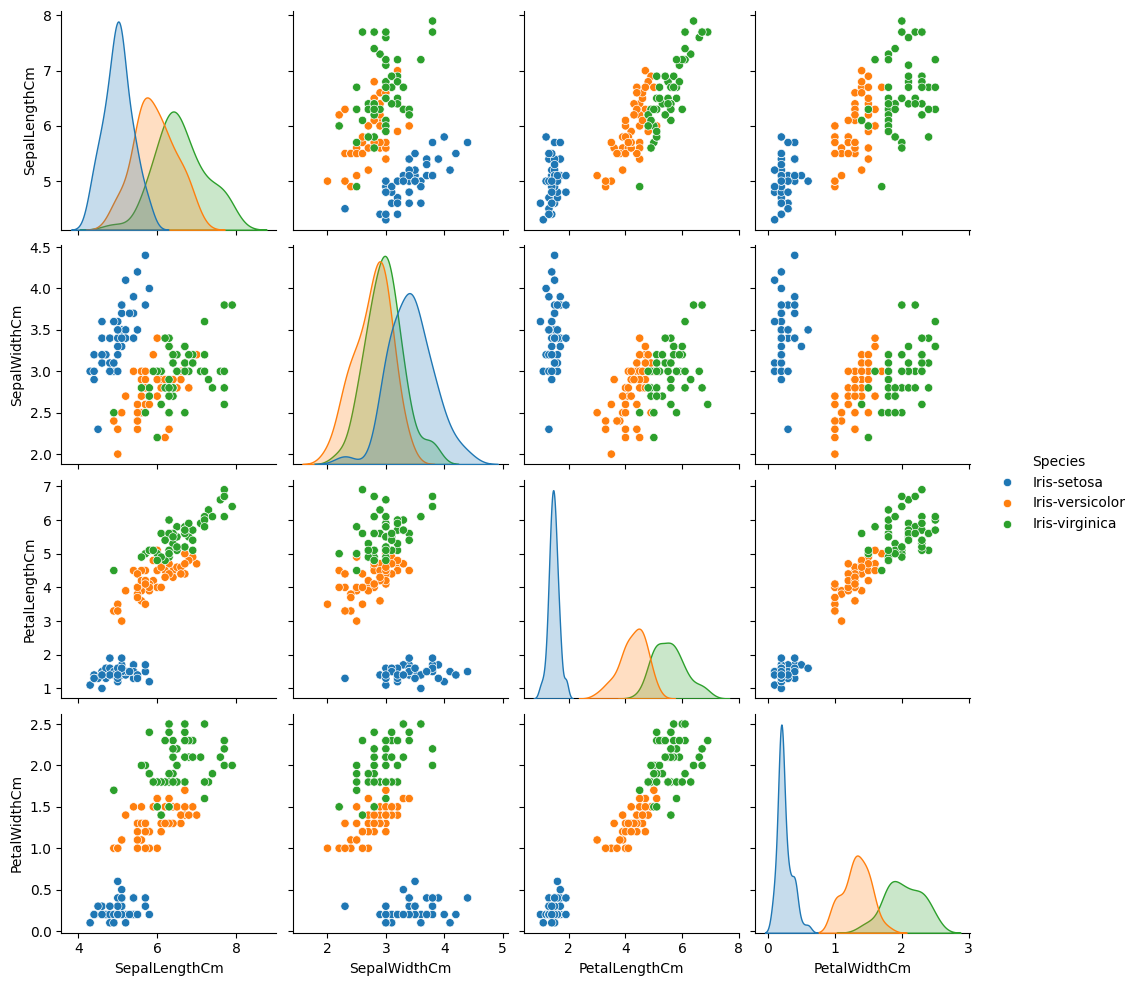

In [4]:
sns.pairplot(df, hue="Species")
plt.show()

### Q1.4 One-hot encoding of a categorical feature

In [5]:
encoded = pd.get_dummies(df, columns=["Species"], dtype=int)    # one 0/1 column per species
encoded.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species_Iris-setosa,Species_Iris-versicolor,Species_Iris-virginica
0,5.1,3.5,1.4,0.2,1,0,0
1,4.9,3.0,1.4,0.2,1,0,0
2,4.7,3.2,1.3,0.2,1,0,0
3,4.6,3.1,1.5,0.2,1,0,0
4,5.0,3.6,1.4,0.2,1,0,0


### Q1.5 Pearson and Spearman correlation matrix with heatmap

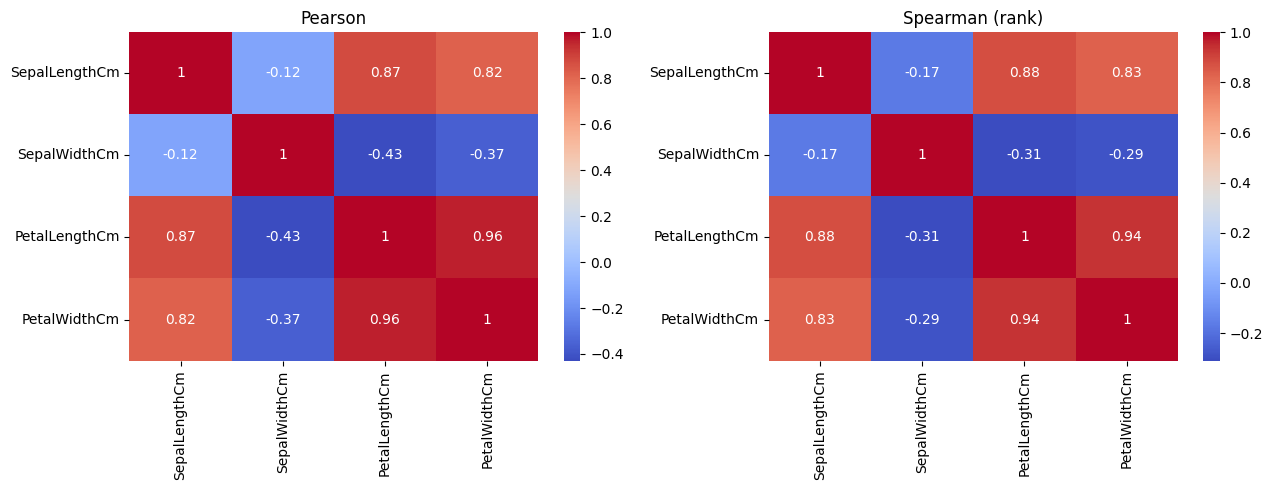

In [6]:
num = df.select_dtypes("number")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(num.corr(method="pearson"), annot=True, cmap="coolwarm", ax=axes[0])
axes[0].set_title("Pearson")
sns.heatmap(num.corr(method="spearman"), annot=True, cmap="coolwarm", ax=axes[1])
axes[1].set_title("Spearman (rank)")
plt.tight_layout()
plt.show()

---
## Question 2

### Q2.1 Read, preprocess and divide into training (75%) and testing (25%)

In [7]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/Diabetes.csv")
zero_is_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]   # a 0 here is impossible = missing
df[zero_is_missing] = df[zero_is_missing].replace(0, np.nan)
df = df.fillna(df.median())                           # fill with the median
X = StandardScaler().fit_transform(df.drop(columns="Outcome"))
y = df["Outcome"]
print(X.shape, y.value_counts().to_dict())

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

(768, 8) {0: 500, 1: 268}
Train: (576, 8)  Test: (192, 8)


### Q2.2 Build the MLP and evaluate: confusion table and Accuracy

In [8]:
from sklearn.neural_network import MLPClassifier

model = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=1000, random_state=42).fit(X_train, y_train)

In [9]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

y_pred = model.predict(X_test)
print("Confusion table:")
print(confusion_matrix(y_test, y_pred))
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, average="macro"), 4))
print("Recall   :", round(recall_score(y_test, y_pred, average="macro"), 4))
print("F-measure:", round(f1_score(y_test, y_pred, average="macro"), 4))

Confusion table:
[[94 29]
 [30 39]]
Accuracy : 0.6927
Precision: 0.6658
Recall   : 0.6647
F-measure: 0.6652


### Q2.3 Optimise (GridSearchCV), compare and plot

Best parameters: {'alpha': 0.01, 'hidden_layer_sizes': (16,), 'learning_rate_init': 0.01}
{'Default MLP': 0.6927083333333334, 'Tuned MLP': 0.6979166666666666}


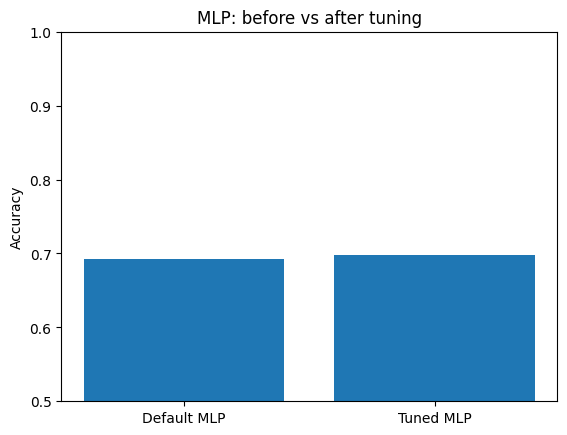

In [10]:
from sklearn.model_selection import GridSearchCV

grid = {"hidden_layer_sizes": [(16,), (32, 16)], "alpha": [0.0001, 0.01, 0.1], "learning_rate_init": [0.001, 0.01]}
search = GridSearchCV(MLPClassifier(max_iter=1000, random_state=42), grid, cv=5, n_jobs=-1).fit(X_train, y_train)
print("Best parameters:", search.best_params_)

scores = {"Default MLP": accuracy_score(y_test, y_pred), "Tuned MLP": accuracy_score(y_test, search.predict(X_test))}
print(scores)
plt.bar(scores.keys(), scores.values())
plt.ylim(0.5, 1)
plt.ylabel("Accuracy")
plt.title("MLP: before vs after tuning")
plt.show()